# 02 · Results
Run the models first (`make baseline models hybrids`, or `uv run vgrec run --model <name>`). This notebook only reads `results/`; it works with whichever models have results.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from vgrec.config import RESULTS_DIR
from vgrec.data import load_dataset, load_items
from vgrec.experiment import report

tables = report()
summary = tables['summary']
cols = ['users', 'precision@10', 'recall@10', 'ndcg@10', 'hit_rate@10', 'coverage',
        'personalization', 'fit_s', 'score_s']
test = summary[summary['stage'] == 'test'].set_index('model')[cols]
test.sort_values('ndcg@10', ascending=False).round(4)

,users,precision@10,recall@10,ndcg@10,hit_rate@10,coverage,personalization,fit_s,score_s
model,,,,,,,,,
hybrid_pop,10049,0.0073,0.0412,0.0218,0.0686,0.1370,0.5350,28.65,15.10
hybrid,10049,0.0061,0.0326,0.0204,0.0548,0.1298,0.9822,26.48,14.05
als,10049,0.0055,0.0299,0.0187,0.0510,0.0872,0.9804,19.29,1.43
ncf,10049,0.0057,0.0303,0.0158,0.0548,0.0007,0.0211,4.79,5.98
popularity,10049,0.0056,0.0302,0.0149,0.0535,0.0006,0.0110,0.00,1.44
content,10049,0.0029,0.0162,0.0099,0.0276,0.6260,0.9980,7.05,13.28


## Validation vs. test (did tuning overfit the valid stage?)

In [2]:
summary.pivot_table(index='model', columns='stage', values='ndcg@10').round(4)

stage,test,valid
model,,
als,0.0187,0.0186
content,0.0099,0.0088
hybrid,0.0204,0.0192
hybrid_pop,0.0218,0.0247
ncf,0.0158,0.0134
popularity,0.0149,0.0178


## NDCG@10 by history length (the proposal's *limited histories* question)

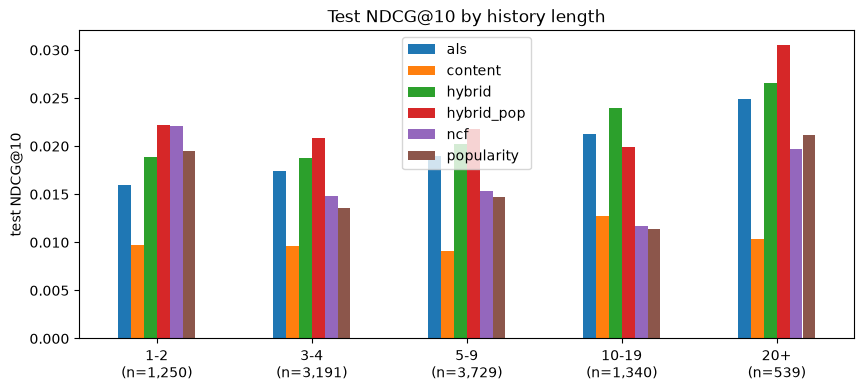

In [3]:
by_hist = tables['ndcg_by_history']
ax = by_hist.drop(columns='users').plot.bar(figsize=(10, 4), ylabel='test NDCG@10',
                                             title='Test NDCG@10 by history length')
ax.set_xticklabels([f'{b}\n(n={n:,})' for b, n in by_hist['users'].items()], rotation=0);

## Are the differences significant? (paired bootstrap over test users)

In [4]:
tables['significance'].round(5)

,a,b,metric,mean_diff,ci_low,ci_high,p_value
0,hybrid,als,ndcg,0.00173,0.00112,0.00233,0.00000
1,hybrid,content,ndcg,0.01056,0.00850,0.01261,0.00000
2,hybrid_pop,hybrid,ndcg,0.00133,-0.00026,0.00296,0.11155
3,hybrid_pop,popularity,ndcg,0.00692,0.00531,0.00853,0.00000
4,als,popularity,ndcg,0.00386,0.00169,0.00613,0.00112
5,ncf,als,ndcg,-0.00294,-0.00521,-0.00054,0.01456


## Hybrid weight sweeps (valid stage)

In [5]:
for name in ('hybrid', 'hybrid_pop'):
    path = RESULTS_DIR / name / 'valid_grid.csv'
    if path.exists():
        grid = pd.read_csv(path)
        print(name)
        display(grid.pivot_table(index='alpha', columns=['beta', 'adaptive_k'], values='ndcg@10').round(4))

hybrid


beta           0.0                        
adaptive_k     0.0     1.0     2.0     5.0
alpha                                     
0.3         0.0150  0.0138  0.0127  0.0115
0.4         0.0173  0.0158  0.0146  0.0125
0.5         0.0185  0.0174  0.0163  0.0137
0.6         0.0190  0.0182  0.0172  0.0150
0.7         0.0192  0.0187  0.0181  0.0160
0.8         0.0189  0.0189  0.0184  0.0170
0.9         0.0189  0.0189  0.0185  0.0174

hybrid_pop


beta           0.1             0.2             0.3             0.4        
adaptive_k     0.0     2.0     0.0     2.0     0.0     2.0     0.0     2.0
alpha                                                                     
0.4         0.0192  0.0164  0.0225  0.0200  0.0240  0.0226  0.0232  0.0222
0.5         0.0203  0.0181  0.0232  0.0215  0.0247  0.0236  0.0236  0.0227
0.6         0.0208  0.0190  0.0230  0.0222  0.0242  0.0241  0.0236  0.0232
0.7         0.0206  0.0199  0.0226  0.0228  0.0241  0.0244  0.0241  0.0235

## Qualitative check: one user's history and each model's top-10

In [6]:
ds = load_dataset()
titles = load_items()['title'].str.slice(0, 70)
models = [p.parent.name for p in sorted(RESULTS_DIR.glob('*/test_topk.npy'))]
per_user = pd.read_parquet(RESULTS_DIR / models[0] / 'test_per_user.parquet')
row = int(np.flatnonzero(per_user['n_history'].between(3, 6))[0])
user = int(per_user.loc[row, 'user_idx'])
mine = ds.interactions[ds.interactions['user_idx'] == user].sort_values('timestamp')
print('History:', *titles.iloc[mine.loc[mine['split'] != 'test', 'item_idx']], sep='\n  ')
print('Interacted with next (test):', *titles.iloc[mine.loc[mine['split'] == 'test', 'item_idx']], sep='\n  ')
pd.DataFrame({m: titles.iloc[np.load(RESULTS_DIR / m / 'test_topk.npy')[row]].tolist() for m in models})

History:
  NEOGEO Mini International
  NEOGEO mini PAD(White)
  Corsair K95 RGB Platinum XT Mechanical Gaming Keyboard, Backlit RGB LE
  Logitech G502 Lightspeed Wireless Gaming Mouse with Hero 25K Sensor, P
  Minecraft: Starter Collection – Windows 10 [Digital Code]
  HyperX Cloud II Wireless - Gaming Headset for PC, PS4/PS5, Nintendo Sw
Interacted with next (test):
  PORTHOLIC Wii to HDMI Converter 1080P for Full HD Device, Wii HDMI Ada


,als,content,hybrid,hybrid_pop,ncf,popularity
0,"Logitech G640 Large Cloth Gaming Mouse Pad, Op...",HyperX Cloud Flight S - Wireless Gaming Headse...,"Logitech G640 Large Cloth Gaming Mouse Pad, Op...",Pokémon Legends: Arceus - Nintendo Switch,Pokémon Legends: Arceus - Nintendo Switch,Pokémon Legends: Arceus - Nintendo Switch
1,Logitech G815 LIGHTSYNC RGB Mechanical Gaming ...,HyperX Cloud Core – Wireless Gaming Headset fo...,Logitech G815 LIGHTSYNC RGB Mechanical Gaming ...,Elden Ring - PlayStation 4,"SanDisk 128GB microSDXC-Card, Licensed for Nin...",Elden Ring - PlayStation 4
2,Turtle Beach Ear Force Headset Audio Controlle...,"HyperX Cloud Flight - Wireless Gaming Headset,...","HyperX Cloud Flight - Wireless Gaming Headset,...",Meta Quest 2 — Advanced All-In-One Virtual Rea...,Meta Quest 2 — Advanced All-In-One Virtual Rea...,Meta Quest 2 — Advanced All-In-One Virtual Rea...
3,Sennheiser GAME ZERO Special Edition Gaming He...,"HyperX Cloud II Gaming Headset - 53mm Drivers,...",Sennheiser GAME ZERO Special Edition Gaming He...,Horizon Forbidden West Collector's Edition - P...,PlayStation DualSense Wireless Controller – Ga...,Horizon Forbidden West Collector's Edition - P...
4,HyperX Alloy Origins - Mechanical Gaming Keybo...,"HyperX Cloud Stinger S – Gaming Headset, for P...",Turtle Beach Ear Force Headset Audio Controlle...,PlayStation DualSense Wireless Controller – Ga...,amFilm Tempered Glass Screen Protector for Nin...,PlayStation DualSense Wireless Controller – Ga...
5,Logitech G903 LIGHTSPEED Gaming Mouse with POW...,HyperX Cloud II Gaming Headset for PC & PS4 - ...,HyperX Alloy Origins - Mechanical Gaming Keybo...,"HyperX Cloud Flight - Wireless Gaming Headset,...",KIWI design Head Strap with Halo Controller Pr...,Nintendo Switch – OLED Model Splatoon 3 Specia...
6,SteelSeries Arctis 7 - Lossless Wireless Gamin...,HyperX Cloud II Gaming Headset - 7.1 Surround ...,SteelSeries Arctis 7 - Lossless Wireless Gamin...,Logitech G502 HERO High Performance Wired Gami...,DualShock 4 Wireless Controller for PlayStatio...,KIWI design Head Strap with Halo Controller Pr...
7,Logitech G502 HERO High Performance Wired Gami...,HyperX Cloud Revolver S - Gaming Headset with ...,HyperX Alloy Core RGB – Membrane Gaming Keyboa...,Logitech G815 LIGHTSYNC RGB Mechanical Gaming ...,Horizon Forbidden West Collector's Edition - P...,Gran Turismo 7 Launch Edition - PlayStation 5
8,HyperX Alloy Core RGB – Membrane Gaming Keyboa...,HyperX Cloud Revolver - Gaming Headset with Hy...,Logitech G903 LIGHTSPEED Gaming Mouse with POW...,Xbox Elite Wireless Controller Series 2 – Black,Nintendo Switch – OLED Model Splatoon 3 Specia...,"SanDisk 128GB microSDXC-Card, Licensed for Nin..."
9,"Corsair M65 RGB Ultra Wireless, Tunable FPS Wi...",HyperX Cloud Revolver S Gaming Headset with Do...,Logitech G Logitech G935 Over Ear Wireless Hea...,KIWI design Head Strap with Halo Controller Pr...,Cyberpunk 2077 - PC [Game Download Code in Box],Kirby and the Forgotten Land - Nintendo Switch


## Takeaways

- **Best model: the hybrid with a popularity prior (`hybrid_pop`)**, at test NDCG@10 0.0218, Recall@10 0.0412 and HR@10 0.0686. Its NDCG edge over the plain CF + content hybrid (+0.0013, 95% CI [−0.0003, +0.0030], p = 0.11) is **not significant**. Its Recall@10 (+26%) and HR@10 (+25%) gains are large, but it costs personalization (0.53 vs. 0.98).
- **The proposal's hybrid works.** CF + content beats ALS alone by +0.0017 NDCG@10 (+9%, CI [+0.0011, +0.0023]) and content alone by +0.0106. The gain is largest for users with only 1–2 history items (0.0189 vs. 0.0160, +18%), which supports the limited-histories hypothesis. A history-adaptive CF weight (0.0189 valid) did not beat a fixed α = 0.7 (0.0192).
- **Time decay mattered more than any classic hyperparameter.** Best valid NDCG@10 rose by +57% for ALS (0.0119 → 0.0186), +37% for content (0.0064 → 0.0088) and +78% for NeuMF (0.0075 → 0.0134). Popularity over the last 180 days is 3.2× all-time popularity (0.0178 vs. 0.0056). This follows from popularity drift: the history's top-10 items never reappear in the target period's top 10.
- **NeuMF is significantly worse than ALS** (−0.0029, CI [−0.0052, −0.0005]). Its best configuration recommends nearly the same ten items to everyone (personalization 0.02, coverage 0.07%), so it behaves like a recency-weighted popularity ranker. That is also why it does well for 1–2-item users and poorly elsewhere.
- **Cost vs. accuracy (test stage):** popularity takes about 0 s to fit and 1.4 s to score, and ALS 19 s and 1.4 s. Content scoring is the expensive part (13 s for 10K users), so the hybrids cost roughly the sum of their parts (26–29 s fit, 14–15 s score) for a +9–17% NDCG gain over ALS.
- **Coverage and personalization trade-offs:** content covers 63% of the catalog, the hybrids 13–14%, ALS 9%, and popularity and NeuMF under 0.1%. Valid → test transfer is stable for the personalized models (ALS 0.0186 → 0.0187). Popularity-driven choices degrade (popularity 0.0178 → 0.0149, `hybrid_pop` 0.0247 → 0.0218), because each period's hits differ again. All absolute scores are small because only 43% of test target rows are rankable at all (cold users and new items are dropped).